In [5]:
# Install required libraries
!pip install pandas numpy matplotlib seaborn scikit-learn transformers datasets torch -q

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("All libraries imported successfully!")

All libraries imported successfully!


In [6]:
# Load IMDb dataset

df = pd.read_csv("IMDB Dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

print("\nFirst 5 rows:")
print(df.head())

Dataset loaded successfully!
Shape: (50000, 2)

First 5 rows:
                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive


Dataset Shape:
(50000, 2)

Column Names:
Index(['review', 'sentiment'], dtype='str')

Missing Values:
review       0
sentiment    0
dtype: int64

Sentiment Distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


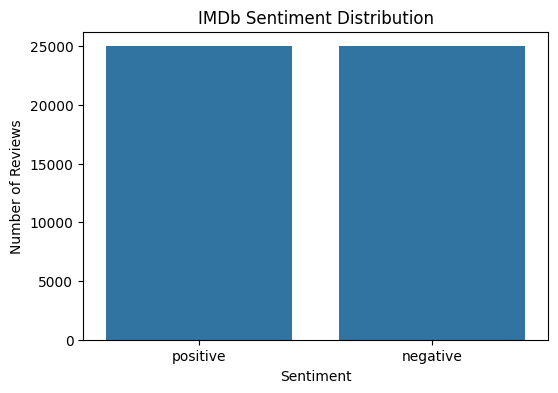

In [4]:
# Basic dataset analysis

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

# Plot sentiment distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="sentiment")
plt.title("IMDb Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

In [5]:
# Convert sentiment labels into numbers

df["label"] = df["sentiment"].map({
    "negative": 0,
    "positive": 1
})

print(df.head())

print("\nLabel Distribution:")
print(df["label"].value_counts())

                                              review sentiment  label
0  One of the other reviewers has mentioned that ...  positive      1
1  A wonderful little production. <br /><br />The...  positive      1
2  I thought this was a wonderful way to spend ti...  positive      1
3  Basically there's a family where a little boy ...  negative      0
4  Petter Mattei's "Love in the Time of Money" is...  positive      1

Label Distribution:
label
1    25000
0    25000
Name: count, dtype: int64


In [6]:
# Basic text preprocessing

import re

def clean_text(text):
    text = re.sub(r"<br\s*/?>", " ", text)   # Remove HTML tags
    text = re.sub(r"\s+", " ", text)        # Remove extra spaces
    text = text.strip()                     # Remove spaces at beginning/end
    return text

df["clean_review"] = df["review"].apply(clean_text)

print("Original Review:")
print(df["review"].iloc[0])

print("\nCleaned Review:")
print(df["clean_review"].iloc[0])

Original Review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show 

In [7]:
# STEP 6: Train-Test Split

from sklearn.model_selection import train_test_split

# Select input text and target label
X = df["clean_review"]
y = df["label"]

# Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())

Training reviews: 40000
Testing reviews: 10000

Training labels:
label
1    20000
0    20000
Name: count, dtype: int64

Testing labels:
label
0    5000
1    5000
Name: count, dtype: int64


In [8]:
# STEP 7: DistilBERT Tokenization

from transformers import AutoTokenizer

# Load DistilBERT tokenizer
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

# Tokenize training reviews
train_encodings = tokenizer(
    X_train.tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

# Tokenize testing reviews
test_encodings = tokenizer(
    X_test.tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

print("Tokenization completed successfully!")

print("\nExample original review:")
print(X_train.iloc[0])

print("\nToken IDs:")
print(train_encodings["input_ids"][0][:20])

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

C:\Users\HP\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\HP\.cache\huggingface\hub\models--distilbert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Tokenization completed successfully!

Example original review:
I caught this little gem totally by accident back in 1980 or '81. I was at a revival theatre to see two old silly sci-fi movies. The theatre was packed full and (with no warning) they showed a bunch of sci-fi short spoofs (to get us in the mood). Most were somewhat amusing but THIS came on and, within seconds, the audience was in hysterics! The biggest laugh came when they showed "Princess Laia" having huge cinnamon buns instead of hair on her head. She looks at the camera, gives a grim smile and nods. That made it even funnier! You gotta see "Chewabacca" played by what looks like a Muppet! It was extremely silly and stupid...but I couldn't stop laughing. Most of the dialogue was drowned out because of all the laughter. Also if you know "Star Wars" pretty well it's even funnier--they deliberately poke fun at some of the dialogue. This REALLY works with an audience! A definite 10!

Token IDs:
[101, 1045, 3236, 2023, 2210, 17

In [9]:
# STEP 8: Create PyTorch Dataset

import torch
from torch.utils.data import Dataset

class MovieReviewDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels.tolist()

    def __getitem__(self, idx):
        item = {
            key: torch.tensor(val[idx])
            for key, val in self.encodings.items()
        }
        item["labels"] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)

# Create datasets
train_dataset = MovieReviewDataset(train_encodings, y_train)
test_dataset = MovieReviewDataset(test_encodings, y_test)

print("Training dataset size:", len(train_dataset))
print("Testing dataset size:", len(test_dataset))

Training dataset size: 40000
Testing dataset size: 10000


In [10]:
# STEP 9: Load DistilBERT Model

from transformers import AutoModelForSequenceClassification

# Load pretrained DistilBERT
model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
)

print("DistilBERT model loaded successfully!")
print("Number of output classes:", model.num_labels)

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT model loaded successfully!
Number of output classes: 2


In [12]:
!pip install -U "accelerate>=1.1.0" -q

In [1]:
import accelerate
import transformers

print("Accelerate version:", accelerate.__version__)
print("Transformers version:", transformers.__version__)

Accelerate version: 1.15.0
Transformers version: 5.5.3


In [2]:
# STEP 10: Training Configuration

from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./flickfeel_model",
    num_train_epochs=2,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=100,
    load_best_model_at_end=True,
    report_to="none"
)

print("Training configuration created successfully!")

C:\Users\HP\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Training configuration created successfully!


In [3]:
# STEP 11: Evaluation Metrics

from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(eval_pred):
    predictions, labels = eval_pred

    # Get predicted class
    predictions = np.argmax(predictions, axis=1)

    # Calculate metrics
    accuracy = accuracy_score(labels, predictions)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary"
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

print("Evaluation function created successfully!")

Evaluation function created successfully!


In [7]:
# STEP 12: Create Trainer

from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics
)

print("Trainer created successfully!")

NameError: name 'model' is not defined

In [8]:
# STEP 9: Load DistilBERT Model

from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
)

print("DistilBERT model loaded successfully!")
print("Number of classes:", model.num_labels)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT model loaded successfully!
Number of classes: 2


In [9]:
# STEP 10: Training Configuration

from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./flickfeel_model",
    num_train_epochs=2,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=100,
    load_best_model_at_end=True,
    report_to="none"
)

print("Training configuration created successfully!")

Training configuration created successfully!


In [10]:
# STEP 11: Evaluation Metrics

from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import numpy as np

def compute_metrics(eval_pred):
    predictions, labels = eval_pred

    predictions = np.argmax(predictions, axis=1)

    accuracy = accuracy_score(labels, predictions)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary"
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

print("Evaluation function created successfully!")

Evaluation function created successfully!


In [11]:
# STEP 12: Create Trainer

from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics
)

print("Trainer created successfully!")

NameError: name 'train_dataset' is not defined

In [1]:
# ============================================================
# FLICKFEEL - SENTIMENT ANALYSIS USING DISTILBERT
# Complete setup in ONE Jupyter Notebook cell
# ============================================================


# 2. Import libraries
import pandas as pd
import numpy as np
import re
import torch

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

from torch.utils.data import Dataset

print("Libraries loaded successfully!")

# ============================================================
# 3. LOAD DATASET
# ============================================================

df = pd.read_csv("IMDB Dataset.csv")

print("\nDataset Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

# ============================================================
# 4. CHECK DATASET
# ============================================================

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

# ============================================================
# 5. CONVERT SENTIMENT TO NUMERICAL LABEL
# ============================================================

df["label"] = df["sentiment"].map({
    "negative": 0,
    "positive": 1
})

# ============================================================
# 6. TEXT PREPROCESSING
# ============================================================

def clean_text(text):
    text = re.sub(r"<br\s*/?>", " ", str(text))
    text = re.sub(r"\s+", " ", text)
    text = text.strip()
    return text

df["clean_review"] = df["review"].apply(clean_text)

print("\nExample Cleaned Review:")
print(df["clean_review"].iloc[0])

# ============================================================
# 7. TRAIN-TEST SPLIT
# ============================================================

X = df["clean_review"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Reviews:", len(X_train))
print("Testing Reviews:", len(X_test))

# ============================================================
# 8. DISTILBERT TOKENIZATION
# ============================================================

tokenizer = AutoTokenizer.from_pretrained(
    "distilbert-base-uncased"
)

train_encodings = tokenizer(
    X_train.tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

test_encodings = tokenizer(
    X_test.tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

print("\nTokenization completed!")

# ============================================================
# 9. CREATE PYTORCH DATASET
# ============================================================

class MovieReviewDataset(Dataset):

    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels.tolist()

    def __getitem__(self, idx):
        item = {
            key: torch.tensor(val[idx])
            for key, val in self.encodings.items()
        }

        item["labels"] = torch.tensor(
            self.labels[idx],
            dtype=torch.long
        )

        return item

    def __len__(self):
        return len(self.labels)


train_dataset = MovieReviewDataset(
    train_encodings,
    y_train
)

test_dataset = MovieReviewDataset(
    test_encodings,
    y_test
)

print("PyTorch datasets created!")

# ============================================================
# 10. LOAD DISTILBERT MODEL
# ============================================================

model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
)

print("\nDistilBERT model loaded!")

# ============================================================
# 11. EVALUATION METRICS
# ============================================================

def compute_metrics(eval_pred):

    predictions, labels = eval_pred

    predictions = np.argmax(
        predictions,
        axis=1
    )

    accuracy = accuracy_score(
        labels,
        predictions
    )

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary"
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

print("Evaluation metrics ready!")

# ============================================================
# 12. TRAINING CONFIGURATION
# ============================================================

training_args = TrainingArguments(
    output_dir="./flickfeel_model",

    num_train_epochs=2,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,

    learning_rate=2e-5,

    weight_decay=0.01,

    eval_strategy="epoch",

    save_strategy="epoch",

    logging_strategy="steps",
    logging_steps=100,

    load_best_model_at_end=True,

    report_to="none"
)

print("Training configuration ready!")

# ============================================================
# 13. CREATE TRAINER
# ============================================================

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics
)

print("\n================================================")
print("FLICKFEEL SETUP COMPLETED SUCCESSFULLY!")
print("================================================")

# Check GPU
if torch.cuda.is_available():
    print("GPU Available:", torch.cuda.get_device_name(0))
else:
    print("GPU not available - training will use CPU.")

print("\nReady for model training!")

C:\Users\HP\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Libraries loaded successfully!

Dataset Shape: (50000, 2)

First 5 rows:
                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive

Missing Values:
review       0
sentiment    0
dtype: int64

Sentiment Distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Example Cleaned Review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me. The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no p

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



DistilBERT model loaded!
Evaluation metrics ready!
Training configuration ready!

FLICKFEEL SETUP COMPLETED SUCCESSFULLY!
GPU not available - training will use CPU.

Ready for model training!


In [ ]:
# ============================================================
# STEP 13: TRAIN DISTILBERT MODEL
# ============================================================

print("Starting FlickFeel model training...")
print("Please wait. CPU training can take some time.\n")

# Train the model
train_result = trainer.train()

print("\n==========================================")
print("TRAINING COMPLETED!")
print("==========================================")

# Evaluate model on test dataset
results = trainer.evaluate()

print("\nMODEL EVALUATION RESULTS")
print("------------------------------------------")

print("Accuracy  :", round(results["eval_accuracy"] * 100, 2), "%")
print("Precision :", round(results["eval_precision"] * 100, 2), "%")
print("Recall    :", round(results["eval_recall"] * 100, 2), "%")
print("F1 Score  :", round(results["eval_f1"] * 100, 2), "%")

Starting FlickFeel model training...
Please wait. CPU training can take some time.



C:\Users\HP\anaconda3\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Epoch,Training Loss,Validation Loss
